In [6]:
import numpy as np
from sklearn.metrics import roc_curve, auc, f1_score, accuracy_score, classification_report
from itertools import permutations
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, AutoMinorLocator, FixedLocator
from matplotlib.lines import Line2D
import os
import json

In [7]:
def extract_hard_output(predictions_file):
    y_true = []
    y_pred = []

    with open(predictions_file, "r") as f:
        next(f)

        for line in f:
            line = line.strip()
            if not line:
                continue

            actual, pred = line.split("\t")

            y_true.append(int(actual))
            y_pred.append(int(pred))

    return np.array(y_true), np.array(y_pred)

In [8]:
datasets = [
    "cic-iomt",
    "edge-iiot",
    "iot-nidd",
]

models = [
    "hybrid",
    "hybrid_ampe_probs",
]

tau_values = [
    50,
    100,
    500,
    1000,
    5000,
    10000,
    100000000,
]

base_folder = f"/home/{os.environ['USER']}/qml-nids/Results"
metrics_dir = f"{base_folder}/metrics"
output_dir = f"{base_folder}/plots/oc3"

In [10]:
rows = []

# thresholds
for ds in datasets:
    print(f"{base_folder}/{ds}")

    for m in models:
        model_path = f"{base_folder}/models_outputs/{ds}/time_to_insight/{m}"

        for tau in tau_values[:-1]:
            tau_path = f"{model_path}/tti-threshold_{tau}"

            fold_f1s = []

            with open(f"{model_path}/labels_map.json", "r") as json_file:
                dictionary = json.load(json_file)

            benign_idx = int(
                next(k for k, v in dictionary.items() if v == "benign")
            )

            for f in range(1, 6):
                fold_path = f"{tau_path}/fold_{f}"
                y_true, y_pred = extract_hard_output(
                    f"{fold_path}/hard_output.dat"
                )

                fold_f1s.append(
                    f1_score(
                        y_true,
                        y_pred,
                        average="macro",
                    )
                )

            rows.append(
                {
                    "dataset": ds,
                    "model": m,
                    "tau": tau,
                    "avg_f1": np.mean(fold_f1s) * 100,
                    "std_f1": np.std(fold_f1s) * 100,
                }
            )


# infinity case
for ds in datasets:
    print(f"{base_folder}/{ds}")

    for m in models:
        model_path = f"/{base_folder}/models_outputs/{ds}/trained_models/100perc/{m}"
        fold_f1s = []

        with open(f"{model_path}/labels_map.json", "r") as json_file:
            dictionary = json.load(json_file)

        benign_idx = int(
            next(k for k, v in dictionary.items() if v == "benign")
        )

        for f in range(1, 6):
            fold_path = f"{model_path}/fold_{f}"
            y_true, y_pred = extract_hard_output(
                f"{fold_path}/hard_output.dat"
            )

            fold_f1s.append(
                f1_score(
                    y_true,
                    y_pred,
                    average="macro",
                )
            )

        rows.append(
            {
                "dataset": ds,
                "model": m,
                "tau": 100000000,
                "avg_f1": np.mean(fold_f1s) * 100,
                "std_f1": np.std(fold_f1s) * 100,
            }
        )


df_results = pd.DataFrame(
    rows,
    columns=[
        "dataset",
        "model",
        "tau",
        "avg_f1",
        "std_f1",
    ],
)

/home/vincenzo/qml-nids/Results/cic-iomt
/home/vincenzo/qml-nids/Results/edge-iiot
/home/vincenzo/qml-nids/Results/iot-nidd
/home/vincenzo/qml-nids/Results/cic-iomt
/home/vincenzo/qml-nids/Results/edge-iiot
/home/vincenzo/qml-nids/Results/iot-nidd


In [11]:
df_results = pd.DataFrame(rows, columns=["dataset", "model", "tau", "avg_f1", "std_f1"])
df_results.to_csv(f'{metrics_dir}/oc3_time_to_insight.csv', index=False)
df_results

,dataset,model,tau,avg_f1,std_f1
0,cic-iomt,hybrid,50,27.840366,2.154650
1,cic-iomt,hybrid,100,28.903661,2.217208
2,cic-iomt,hybrid,500,46.914932,1.482224
3,cic-iomt,hybrid,1000,50.453971,1.140562
4,cic-iomt,hybrid,5000,50.953866,0.902903
5,cic-iomt,hybrid,10000,49.601163,1.398597
6,cic-iomt,hybrid_ampe_probs,50,31.201109,1.379659
7,cic-iomt,hybrid_ampe_probs,100,32.125927,1.455837
8,cic-iomt,hybrid_ampe_probs,500,42.089865,3.502455
9,cic-iomt,hybrid_ampe_probs,1000,47.274380,3.594622


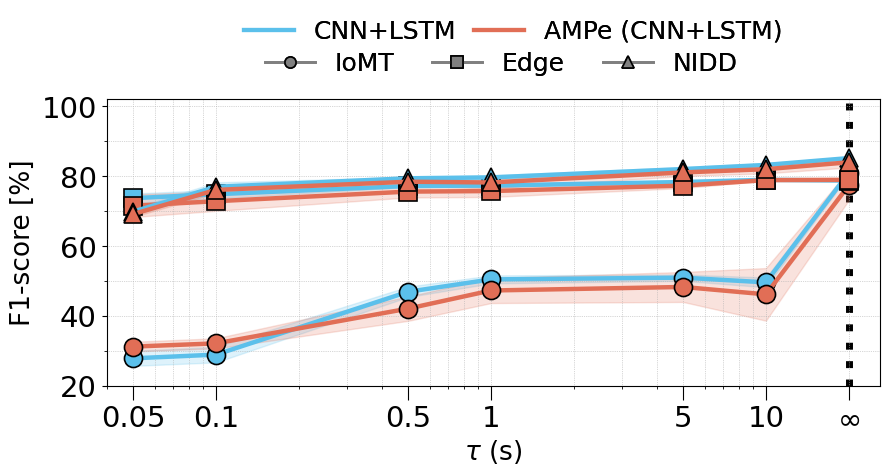

In [12]:
dataset_name_map = {
    "cic-iomt": "IoMT",
    "edge-iiot": "Edge",
    "iot-nidd": "NIDD",
}

dataset_marker_map = {
    "cic-iomt": "o",
    "edge-iiot": "s",
    "iot-nidd": "^",
}

model_name_map = {
    "hybrid": "CNN+LSTM",
    "ampe_fixed_probs": "AMPe (Dense)",
    "hybrid_ampe_probs": "AMPe (CNN+LSTM)",
}

model_colors = {
    "hybrid": "#5BC0EB",
    "ampe_fixed_probs": "#b356e1",
    "hybrid_ampe_probs": "#e16e56",
    "ange_probs": "#84e156",
}


fontsize = 24
linewidth = 3.2

plt.figure(figsize=(9, 4))

model_handles = [
    Line2D(
        [0],
        [0],
        color=model_colors[m],
        lw=3,
        markersize=8,
        linestyle="-",
        label=model_name_map[m],
    )
    for m in models
]

model_labels = [model_name_map[m] for m in models]

ds_handles = [
    Line2D(
        [0],
        [0],
        color="gray",
        lw=2,
        marker=dataset_marker_map[d],
        markersize=8,
        linestyle="-",
        label=dataset_name_map[d],
    )
    for d in datasets
]

ds_labels = [dataset_name_map[d] for d in datasets]

plot_datasets = ["cic-iomt", "edge-iiot", "iot-nidd"]

for dataset in datasets:
    tau_max = 11000

    tau_values_local = [
        50,
        100,
        500,
        1000,
        5000,
        10000,
        50000,
        100000,
        100000000,
    ]

    tau_finite = [
        t for t in tau_values_local[:-1]
        if t <= tau_max
    ]

    tau_plot = tau_finite + [tau_values_local[-1]]

    for m in models:
        model_df = df_results[
            (df_results["model"] == m)
            & (df_results["dataset"] == dataset)
            & (df_results["tau"].isin(tau_plot))
        ].sort_values("tau")

        x = [tau / 1000 for tau in tau_plot]

        y = model_df[f"avg_f1"].tolist()
        std = model_df[f"std_f1"].tolist()

        x[-1] = 2 * x[-2]

        y = np.array(y)
        std = np.array(std)

        plt.plot(
            x,
            y,
            color=model_colors[m],
            linestyle="-",
            linewidth=linewidth,
            marker=dataset_marker_map[dataset],
            markersize=13,
            markeredgecolor="black",
            markeredgewidth=1.2,
            label="_nolegend_",
        )

        plt.fill_between(
            x,
            y - std,
            y + std,
            color=model_colors[m],
            alpha=0.2,
        )


plt.ylim((20, 102))

plt.axvline(
    x=x[-1],
    linestyle=":",
    linewidth=5.0,
    zorder=-1,
    color="k",
)

plt.xticks(fontsize=fontsize - 3)
plt.yticks(fontsize=fontsize - 3)

plt.xlim((0.04, 1.3 * x[-1]))

plt.xlabel(r"$\tau$ (s)", fontsize=fontsize - 5)
plt.ylabel(
    f"F1-score [%]",
    fontsize=fontsize - 5,
)

plt.xscale("log")

plt.grid(True)
plt.grid(
    which="major",
    linestyle=":",
    linewidth=0.5,
)

plt.grid(
    which="minor",
    linestyle=":",
    linewidth=0.5,
)

legend_alg = plt.gcf().legend(
    model_handles,
    model_labels,
    ncol=len(model_handles),
    bbox_to_anchor=(0.9, 1.21),
    frameon=False,
    fontsize=fontsize - 6,
    columnspacing=0.7,
)

legend_ds = plt.gcf().legend(
    ds_handles,
    ds_labels,
    ncol=len(ds_handles),
    bbox_to_anchor=(0.85, 1.13),
    frameon=False,
    fontsize=fontsize - 6,
    columnspacing=1.5,
)

for handle in legend_ds.legend_handles:
    handle.set_markeredgecolor("black")
    handle.set_markeredgewidth(1.2)

plt.gca().add_artist(legend_alg)
plt.gca().add_artist(legend_ds)

plt.gca().xaxis.set_major_formatter(
    ScalarFormatter()
)

plt.gca().xaxis.get_major_formatter().set_scientific(False)
plt.gca().xaxis.get_major_formatter().set_useOffset(False)

plt.gca().set_xticks(
    x[:-1] + [2 * x[-2]]
)

plt.gca().set_xticklabels(
    [str(int(v)) if v >= 1 else str(v) for v in x[:-1]]
    + [r"$\infty$"]
)

plt.gca().tick_params(
    axis="x",
    length=10,
)

plt.gca().yaxis.set_minor_locator(
    FixedLocator(list(np.arange(0, 110, 10)))
)

plt.gca().yaxis.set_major_locator(
    FixedLocator(list(np.arange(0, 110, 20)))
)

plt.tight_layout()

os.makedirs(
    output_dir,
    exist_ok=True,
)

plt.savefig(
    f"{output_dir}/tti_f1.pdf",
    bbox_inches="tight",
)

plt.show()